In [51]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [52]:
DATA_PATH = "../data/telco_customer_churn.csv"

df = pd.read_csv(DATA_PATH)

df.shape

(7043, 21)

In [53]:
new_customer_missing = (
    df["TotalCharges"].str.strip().eq("")
    & df["tenure"].eq(0)
)

df.loc[
    new_customer_missing,
    "TotalCharges"
] = "0"

In [54]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [55]:
X = df.drop(
    columns=["customerID", "Churn"]
)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [57]:
numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [58]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [59]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [60]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_columns
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )
    ]
)

In [61]:
baseline_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

In [62]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [63]:
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

In [64]:
cv_results = cross_validate(
    estimator=baseline_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

In [65]:
metric_rows = []

for metric_name in scoring:
    fold_scores = cv_results[
        f"test_{metric_name}"
    ]

    metric_rows.append({
        "Metrik": metric_name,
        "Ortalama": fold_scores.mean(),
        "Standart Sapma": fold_scores.std(),
        "En Düşük": fold_scores.min(),
        "En Yüksek": fold_scores.max()
    })

cv_summary = pd.DataFrame(metric_rows)

cv_summary.round(3)

,Metrik,Ortalama,Standart Sapma,En Düşük,En Yüksek
0,accuracy,0.802,0.012,0.782,0.816
1,roc_auc,0.846,0.013,0.825,0.863
2,pr_auc,0.661,0.019,0.635,0.686
3,precision,0.652,0.026,0.607,0.684
4,recall,0.544,0.041,0.502,0.622
5,f1,0.592,0.030,0.549,0.642


In [66]:
oof_predictions = cross_val_predict(
    estimator=baseline_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

In [67]:
oof_probabilities = cross_val_predict(
    estimator=baseline_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [68]:
oof_metrics = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ],
    "Değer": [
        accuracy_score(
            y_train,
            oof_predictions
        ),
        roc_auc_score(
            y_train,
            oof_probabilities
        ),
        average_precision_score(
            y_train,
            oof_probabilities
        ),
        precision_score(
            y_train,
            oof_predictions
        ),
        recall_score(
            y_train,
            oof_predictions
        ),
        f1_score(
            y_train,
            oof_predictions
        )
    ]
})

oof_metrics.round(3)

,Metrik,Değer
0,Accuracy,0.802
1,ROC-AUC,0.846
2,PR-AUC,0.658
3,Precision,0.652
4,Recall,0.544
5,F1,0.593


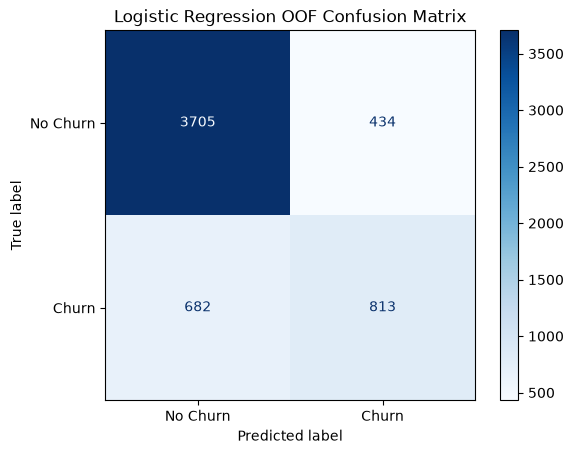

In [69]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    oof_predictions,
    display_labels=[
        "No Churn",
        "Churn"
    ],
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Logistic Regression OOF Confusion Matrix"
)

plt.show()

## Baseline Model Sonuçları

Model yaklaşık %80 accuracy elde etti. Ancak
müşterilerin yaklaşık %73'ünün zaten churn etmeyen sınıfta bulunması
nedeniyle accuracy tek başına yeterli bir performans göstergesi
değil.

Modelin ROC-AUC değeri yaklaşık 0.85 olarak hesaplanmıştır. Bu sonuç,
modelin churn eden ve etmeyen müşterileri sıralama açısından iyi bir
ayırt etme gücüne sahip olduğunu göstermekte. Pozitif sınıfın daha
az bulunduğu bu problemde PR-AUC değerinin yaklaşık 0.66 olması da
anlamlı bir performansa işaret etmektedir.

Precision değerine göre modelin churn edeceğini söylediği müşterilerin
yaklaşık %65'i gerçekten churn etmiştir. Recall değeri ise yaklaşık
%54'tür; yani model churn eden müşterilerin yaklaşık yarısını doğru
tespit ederken önemli bir bölümünü kaçırmakta.

Bununla birlikte müşteri kaybını kaçırmanın maliyeti yüksek olduğundan
özellikle recall değerinin iyileştirilmesi gerekmektedir.

In [70]:
baseline_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [71]:
cv_summary.to_csv(
    "../reports/baseline_cv_metrics.csv",
    index=False
)

In [72]:
oof_metrics.to_csv(
    "../reports/baseline_oof_metrics.csv",
    index=False
)